# GDGoC UGM Academic Hacker 2026/2027 — Prediksi Diagnosis Pasien (4 Kelas)

**Tugas:** memprediksi `target_class` ∈ {`viral_sinusitis`, `viral_pharyngitis`, `acute_bronchitis`, `strep_pharyngitis`}
dari data rekam medis relasional (multi-CSV). **Metrik:** Macro-F1 (rata-rata F1 keempat kelas dengan bobot sama).


## Alur notebook
1. Setup & memuat data
2. EDA tahap 1 (audit kualitas data & kebocoran)
3. Preprocessing / feature engineering
4. EDA tahap 2 (hubungan fitur–kelas pada data bersih)
5. Modeling → 6. Evaluasi → 7. Submission → 8. Catatan write-up

# 1. Setup & Memuat Data

#### 1.1 Impor, konfigurasi, dan pencarian folder data

In [1]:
import re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import chi2_contingency
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

ZIP_NAMA = "gdgoc-ugm-academic-hacker-2026.zip"

def cari_folder():
    """Folder data = folder yang berisi train.csv DAN index_encounters.csv. Jika hanya ada zip, ekstrak ke ./data."""
    kaggle = sorted(Path("/kaggle/input").glob("*")) if Path("/kaggle/input").exists() else []
    kandidat = [Path("../data"), Path("data"), Path("."), Path("../GDGoC-2026"),
                Path("../gdgoc-ugm-academic-hacker-2026")] + kaggle             # UBAH: tambah kandidat bila perlu
    for c in kandidat:
        if (c / "train.csv").exists() and (c / "index_encounters.csv").exists():
            return c
    for z in [Path(ZIP_NAMA), Path("..") / ZIP_NAMA, Path("../data") / ZIP_NAMA, Path("data") / ZIP_NAMA]:
        if z.exists():
            zipfile.ZipFile(z).extractall("data"); return Path("data")
    raise FileNotFoundError("train.csv + index_encounters.csv / zip tidak ditemukan; atur DATA manual")

def sub(nama):
    """Subfolder triase/riwayat. Zip: 'Triase/Triase'; juga menerima versi diratakan."""
    for c in [DATA / nama / nama, DATA / nama, DATA / nama.lower().replace(" ", "-")]:
        if c.is_dir():
            return c
    raise FileNotFoundError(f"subfolder '{nama}' tidak ditemukan di {DATA}")

DATA = cari_folder()
TRIASE, RIWAYAT_DIR = sub("Triase"), sub("Riwayat Medis")
OUT = Path("/outputs"); OUT.mkdir(parents=True, exist_ok=True)

KEY, PASIEN = "encounter_id", "patient_id"          # KEY: kunci sampel -> tabel per-kunjungan | PASIEN: kunci entitas -> tabel statis/riwayat
TARGET, ID = "target_class", "sample_id"
SEED, N_FOLD, N_REPEAT = 42, 5, 3
RUN_ABLATION = False                                # True -> jalankan ablasi di bagian 6 (±6 menit)
RIWAYAT = {                                         # tabel riwayat -> nama kolom tanggalnya
    "conditions": "recorded_at", "medications": "recorded_at", "procedures": "recorded_at",
    "immunizations": "recorded_at", "allergies": "recorded_at", "observations": "observed_at",
    "previous_encounter": "history_start",
}
print("data:", DATA.resolve(), "| LightGBM:", HAS_LGB)

data: C:\INAH-MINE\GEMASTIK-XIX\GDGoC-2026 | LightGBM: True


#### 1.2 Memuat tabel utama

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
waktu = pd.read_csv(DATA / "index_encounters.csv")
waktu["prediction_time"] = pd.to_datetime(waktu["prediction_time"], utc=True)
patients = pd.read_csv(DATA / "patients.csv")

assert TARGET in train.columns and TARGET not in test.columns, "train.csv/test.csv ini bukan milik kompetisi"
print(f"train {train.shape} | test {test.shape} | index_encounters {waktu.shape} | patients {patients.shape}")
print("kolom train:", list(train.columns))
print("kolom test :", list(test.columns))

train (3600, 4) | test (1400, 3) | index_encounters (5000, 3) | patients (5000, 10)
kolom train: ['sample_id', 'patient_id', 'encounter_id', 'target_class']
kolom test : ['sample_id', 'patient_id', 'encounter_id']


**Temuan:** train 3.600 baris, test 1.400 baris, tiap sampel = 1 pasien = 1 kunjungan.

#### Sel 1.3 Fungsi `norm()` dan `angka()` (pembersih teks & angka)

In [3]:
def norm(s):
    """teks → huruf kecil, simbol jadi spasi (menyatukan 'Cough / productive' dan 'cough productive')."""
    return s.astype(str).str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()

def angka(s):
    """'USD 1,234' / '$1,234' / '115.6k' / '28,02' → float. Koma = ribuan kalau diikuti 3 digit, selain itu desimal."""
    s = s.astype(str).str.lower().str.replace(r"usd|\$|\s", "", regex=True)
    kali = np.where(s.str.endswith("k"), 1000, 1)
    s = s.str.rstrip("k").str.replace(r",(?=\d{3}(\D|$))", "", regex=True).str.replace(",", ".")
    return pd.to_numeric(s, errors="coerce") * kali

# uji kecil: fungsi pembersih harus benar SEBELUM dipakai di seluruh data
assert angka(pd.Series(["USD 1,234", "$34,487", "115.6k", "28,02", "0,9", "12679.0", None])).round(2).tolist()[:6] == \
    [1234, 34487, 115600, 28.02, 0.9, 12679]

- `norm()`: nama gejala yang sama ditulis berbeda (`Cough / productive` vs `cough productive`) dihitung sebagai gejala berbeda.
- `angka()`: nilai seperti `USD 1,234`, `$34,487`, `115.6k`, dan `28,02` (koma desimal) tidak bisa dikonversi ke angka. Aturan komanya penting: koma **diikuti tepat 3 digit** dianggap pemisah ribuan (`34,487`), selain itu dianggap koma desimal (`28,02`). Notasi `k` dikali 1000.
- `assert` di akhir berfungsi sebagai *unit test*: kalau seseorang mengubah regex dan merusak parsing, notebook langsung berhenti, bukan diam-diam menghasilkan fitur salah.


# 2. EDA Tahap 1 — Audit Kualitas Data dan Kebocoran

## 2.1 Gambaran umum

#### 2.1.1 Distribusi kelas dan baseline

                   jumlah  persen
target_class                     
viral_sinusitis      1480    41.1
viral_pharyngitis     985    27.4
acute_bronchitis      940    26.1
strep_pharyngitis     195     5.4
rasio kelas terbanyak : tersedikit = 7.6
macro-F1 jika selalu menebak kelas terbanyak: 0.146


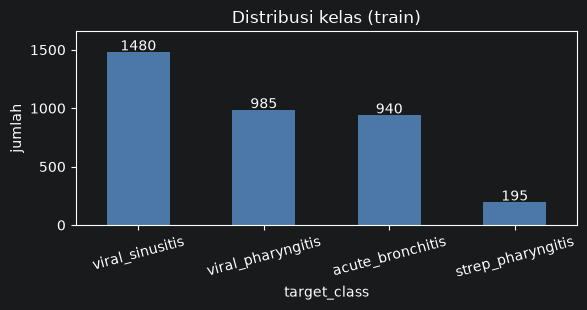

In [4]:
vc = train[TARGET].value_counts()
print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(train) * 100).round(1)}))
print("rasio kelas terbanyak : tersedikit =", round(vc.max() / vc.min(), 1))

tebak_mayoritas = np.full(len(train), vc.idxmax())
print("macro-F1 jika selalu menebak kelas terbanyak:",
      round(f1_score(train[TARGET], tebak_mayoritas, average="macro"), 3))

ax = vc.plot.bar(color="#4C78A8", figsize=(6, 3.2), rot=15)
ax.set_title("Distribusi kelas (train)"); ax.set_ylabel("jumlah"); ax.set_ylim(0, vc.max() * 1.12)
for i, v in enumerate(vc.values):
    ax.text(i, v + 15, f"{v}", ha="center")
plt.tight_layout(); plt.show()

**Temuan:**
- Kelas **tidak seimbang**: `viral_sinusitis` 41,1%, `viral_pharyngitis` 27,4%, `acute_bronchitis` 26,1%, dan `strep_pharyngitis` hanya **5,4%** (195 sampel); rasio terbesar:terkecil 7,6.
- Menebak kelas terbanyak terus-menerus memberi **macro-F1 hanya 0,146** (akurasinya 41%, tetapi tiga kelas lain F1-nya nol). Inilah alasan metrik kompetisi adalah macro-F1: kelas kecil bobotnya sama dengan kelas besar.

**Implikasi desain:** (1) validasi harus **stratified** agar proporsi kelas kecil terjaga di tiap fold; (2) keputusan akhir perlu **penyesuaian bobot kelas** sebab argmax probabilitas cenderung mengabaikan kelas 5%.

#### 2.1.2 Inventaris seluruh file

In [5]:
inventaris = []
for folder in (DATA, TRIASE, RIWAYAT_DIR):
    for f in sorted(folder.glob("*.csv")):
        d = pd.read_csv(f)
        inventaris.append({
            "file": str(f.relative_to(DATA)),
            "baris": len(d),
            "n_encounter": d[KEY].nunique() if KEY in d.columns else None,
            "n_pasien": d[PASIEN].nunique() if PASIEN in d.columns else None,
            "kosong_maks_%": round(d.isna().mean().max() * 100, 1),
            "kolom": ", ".join(d.columns),
        })
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
inventaris = pd.DataFrame(inventaris)
inventaris

,file,baris,n_encounter,n_pasien,kosong_maks_%,kolom
0,DATA_DICTIONARY.csv,87,NaN,NaN,0.0,"file, column, semantic_type, model_role, notes"
1,index_encounters.csv,5000,5000.0,5000.0,0.0,"patient_id, encounter_id, prediction_time"
2,patients.csv,5000,NaN,5000.0,42.3,"patient_id, age_at_visit, gender, race, ethnicity, city, county, state, income_at_visi..."
3,sample_submission.csv,1400,NaN,NaN,100.0,"sample_id, target_class"
4,test.csv,1400,1400.0,1400.0,0.0,"sample_id, patient_id, encounter_id"
5,train.csv,3600,3600.0,3600.0,0.0,"sample_id, patient_id, encounter_id, target_class"
6,Triase\Triase\presenting_complaints.csv,5000,5000.0,5000.0,0.0,"patient_id, encounter_id, presenting_complaints_text"
7,Triase\Triase\triage_symptom_severity.csv,16594,4961.0,4961.0,4.6,"patient_id, encounter_id, observed_at, symptom_concept, severity_score"
8,Triase\Triase\triage_symptoms.csv,19065,5000.0,5000.0,0.0,"patient_id, encounter_id, observed_at, symptom_concept"
9,Triase\Triase\triage_vitals.csv,30000,5000.0,5000.0,11.1,"patient_id, encounter_id, measured_at, vital_name, value, unit"


> **Alasan — Sel 5**

**Apa:** satu tabel ringkas berisi jumlah baris, jumlah kunjungan/pasien unik, persentase kosong tertinggi, dan daftar kolom untuk **setiap** CSV.

**Mengapa:** pada data multi-tabel, hal pertama yang harus dipahami adalah *granularitas* tiap tabel (satu baris mewakili apa?). Dari sini ditentukan cara menggabungkannya ke tabel utama:
- **1 baris per pasien** (`patients`): cukup `merge`.
- **Banyak baris per kunjungan** (`triage_vitals` 30.000 baris, `triage_symptoms` 19.065 baris): *tabel long* → harus dipivot/diringkas menjadi satu baris per kunjungan.
- **Banyak baris per pasien dengan tanggal** (tujuh tabel riwayat): harus **difilter waktu** lebih dulu, baru diringkas.

**Temuan:** `patients` punya kolom dengan kosong hingga 42,3% (kota); `triage_symptom_severity` hanya mencakup 4.961 dari 5.000 kunjungan; `allergies` hanya 2 baris (nyaris tidak berguna).

## 2.2 Audit tabel pasien

#### 2.2.1 Audit umur

In [6]:
AUDIT = []                                           # tabel temuan kualitas data → bahan write-up

patients.info()
umur = patients["age_at_visit"]
n_999 = int((umur == 999).sum())
n_luar = int((umur.notna() & (umur != 999) & ~umur.between(0, 120)).sum())   # nilai tak masuk akal selain 999
print(f"umur: kode 999 = {n_999} | di luar 0-120 selain 999 = {n_luar} | kosong = {umur.isna().sum()}")
print(umur[umur.between(0, 120)].describe().round(1).to_string())
AUDIT.append(("umur kode 999 / di luar 0-120", n_999 + n_luar, "diganti NaN"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   patient_id        5000 non-null   object 
 1   age_at_visit      4940 non-null   float64
 2   gender            5000 non-null   object 
 3   race              5000 non-null   object 
 4   ethnicity         4856 non-null   object 
 5   city              2884 non-null   object 
 6   county            4492 non-null   object 
 7   state             5000 non-null   object 
 8   income_at_visit   4545 non-null   object 
 9   marital_at_visit  3193 non-null   object 
dtypes: float64(1), object(9)
memory usage: 390.8+ KB
umur: kode 999 = 19 | di luar 0-120 selain 999 = 0 | kosong = 60
count    4921.0
mean       38.8
std        21.4
min         0.0
25%        20.5
50%        38.3
75%        56.0
max        90.0


**Temuan:** ada **19 baris berkode `999`** (kode "kosong" yang menyamar sebagai angka) dan 60 baris kosong sungguhan; tidak ada nilai mustahil lain. Setelah `999` dibuang, sebaran umur wajar (rata-rata 38,8; rentang 0–90).

**Keputusan:** `999` diganti `NaN` (bukan dihapus barisnya). **Baris tidak boleh dibuang**, terutama di test, karena setiap sampel test harus tetap mendapat prediksi. Model berbasis pohon menangani `NaN` secara native. Jika `999` dibiarkan, model menganggap ada pasien berusia 999 tahun dan memotong pohon di sekitar angka itu.

#### 2.2.2 Audit income

In [7]:
inc = patients["income_at_visit"].astype("string").str.strip()
jenis = pd.Series("lainnya", index=inc.index)
POLA = {
    "angka polos (12679.0)": r"\d+(\.\d+)?",
    "singkatan k (115.6k)": r"(?i)[\d.,]+k",
    "dolar ($34,487)": r"\$[\d,.]+",
    "USD (USD 1,234)": r"(?i)usd\s*[\d,.]+",
}
for nama, pola in POLA.items():
    jenis[inc.str.fullmatch(pola).fillna(False).astype(bool)] = nama
jenis[inc.isna()] = "kosong"
print("format income:")
print(pd.DataFrame({"jumlah": jenis.value_counts(), "contoh": inc.groupby(jenis).first()}).to_string())
n_campur = int((~jenis.isin(["kosong", "angka polos (12679.0)"])).sum())
AUDIT.append(("income berformat non-polos (USD/$/k/lainnya)", n_campur, "angka(): buang simbol, 'k' x1000, koma ribuan"))
AUDIT.append(("income kosong", int((jenis == "kosong").sum()), "dibiarkan NaN"))

format income:
                       jumlah       contoh
USD (USD 1,234)            71  USD 122,462
angka polos (12679.0)    3855     620511.0
dolar ($34,487)           232      $51,777
kosong                    455         <NA>
lainnya                   225       36,523
singkatan k (115.6k)      162         0.0k



**Temuan:** hanya **3.855** nilai yang berupa angka polos; **690 nilai** memakai format lain — `$51,777` (232), `36,523` tanpa simbol (225), `0.0k`/`115.6k` (162), `USD 122,462` (71) — dan 455 kosong. Kalau dipaksa `pd.to_numeric`, 690 nilai itu menjadi `NaN` dan informasi pendapatan hilang diam-diam.

**Keputusan:** semua format diselesaikan oleh `angka()` (buang simbol, `k`×1000, koma ribuan). Yang benar-benar kosong dibiarkan `NaN`.

#### 2.2.3 Audit status pernikahan dan kolom kategori

In [8]:
mar = patients["marital_at_visit"].dropna().astype(str)
print("marital (mentah):", mar.value_counts().to_dict())
kata_penuh = mar[mar.str.len() > 1]                          # "Married", "Single", ... (bukan kode 1 huruf)
bentrok = kata_penuh.groupby(kata_penuh.str[0]).nunique()    # huruf awal yang dipakai >1 kata berbeda
print("huruf awal yang bentrok (>1 status berbeda):", bentrok[bentrok > 1].to_dict() or "tidak ada")

KAT = ["gender", "race", "ethnicity", "county"]
print("\nkardinalitas:", patients[KAT].nunique().to_dict())
for c in KAT:
    print(f"{c:10s}", patients[c].value_counts(dropna=False).head(5).to_dict())

marital (mentah): {'M': 1852, 'S': 621, 'D': 455, 'W': 116, 'Married': 80, 'Divorced': 32, 'Single': 27, 'Widowed': 10}
huruf awal yang bentrok (>1 status berbeda): tidak ada

kardinalitas: {'gender': 2, 'race': 6, 'ethnicity': 2, 'county': 58}
gender     {'F': 2645, 'M': 2355}
race       {'white': 4104, 'black': 431, 'asian': 326, 'other': 63, 'hawaiian': 47}
ethnicity  {'nonhispanic': 4332, 'hispanic': 524, nan: 144}
county     {'Middlesex County': 1065, 'Worcester County': 512, nan: 508, 'Suffolk County': 486, 'Essex County': 469}


**Temuan:** tidak ada huruf awal yang bentrok, jadi `str[0]` aman. Kolom `county` berkardinalitas tinggi (58), `race` 6, `ethnicity` 2, `gender` 2.

**Catatan:** kardinalitas `county` yang tinggi berisiko overfit bila dipakai sebagai kategori; model berbasis pohon cukup tahan, tetapi kontribusi kolom demografi sebaiknya diuji (lihat ablasi di bagian 6.4 untuk vital dan riwayat).

## 2.3 Audit triase

#### 2.3.1 Audit tanda vital

In [9]:
v = pd.read_csv(TRIASE / "triage_vitals.csv")
n_enc = len(train) + len(test)                                  # jumlah kunjungan seluruhnya
mentah = v["value"].astype(str)
n_koma_desimal = int(mentah.str.contains(r",\d{1,2}$").sum())   # '28,02' -> koma = desimal
n_koma_ambigu = int(mentah.str.contains(r",\d{3}$").sum())      # ',ddd' -> ribuan ATAU desimal 3 digit?
v["nilai"] = angka(v["value"])
n_gagal = int(v["nilai"].isna().sum() - v["value"].isna().sum())  # nilai ada, tetapi tidak terbaca angka
print(f"baris {len(v)} | kunjungan {v[KEY].nunique()} dari {n_enc} | koma desimal {n_koma_desimal} | koma ambigu {n_koma_ambigu} | gagal parse {n_gagal}")

# satuan beda skala: median satuan itu vs median vital itu (mis. 10,5 kPa vs 79 mmHg)
med_vital = v.groupby("vital_name")["nilai"].transform("median")
med_unit = v.groupby(["vital_name", "unit"])["nilai"].transform("median")
rasio = med_unit / med_vital
beda_skala = rasio.notna() & ~rasio.between(0.5, 2)
dobel = int(v.duplicated([KEY, "vital_name"], keep=False).sum())   # baris yang berbagi (kunjungan, vital) yang sama
print(f"Jumlah data dengan perbedaan skala: {beda_skala.sum()} | baris terindikasi duplikat: {dobel}")

ringkasan = (v.assign(median_unit=med_unit, median_vital=med_vital, rasio=rasio, beda_skala=beda_skala)
               .groupby(["vital_name", "unit"])
               .agg(jumlah_data=("nilai", "count"), median_unit=("median_unit", "first"),
                    median_vital=("median_vital", "first"), rasio=("rasio", "first"), beda_skala=("beda_skala", "first"))
               .reset_index())
print(ringkasan.to_string(index=False))
AUDIT.append(("vital: koma desimal ('28,02')", n_koma_desimal, "angka(): koma -> titik"))
AUDIT.append(("vital: satuan beda skala (kPa, fraction)", int(beda_skala.sum()), "KONVERSI: kPa x7.50062, fraction x100"))

baris 30000 | kunjungan 5000 dari 5000 | koma desimal 112 | koma ambigu 0 | gagal parse 0
Jumlah data dengan perbedaan skala: 1049 | baris terindikasi duplikat: 0
      vital_name        unit  jumlah_data  median_unit  median_vital    rasio  beda_skala
             BMI       kg/m2         3114       27.790         27.79 1.000000       False
    Diastolic BP         kPa          315       10.530         78.00 0.135000        True
    Diastolic BP        mmHg         4407       79.000         78.00 1.012821       False
      Heart rate        /min         4031       80.000         80.00 1.000000       False
      Heart rate   beats/min          661       80.000         80.00 1.000000       False
Respiratory rate        /min         4057       14.000         14.00 1.000000       False
Respiratory rate breaths/min          656       14.000         14.00 1.000000       False
            SpO2           %         4275       94.000         94.00 1.000000       False
            SpO2    fractio


**Temuan:**
- **Koma desimal:** 112 nilai bertulis seperti `28,02`. Tidak ada koma "ambigu" (`,ddd`), sehingga aturan di `angka()` tidak salah tafsir.
- **Satuan beda skala:** tekanan darah ada yang dalam **kPa** (sistolik median 15,9 vs 118 mmHg; rasio 0,13) dan SpO2 ada yang berupa **fraction** (0,94 vs 94%; rasio 0,01). Total **1.049 baris** berbeda skala. Rasio median per satuan terhadap median vital dipakai sebagai detektor: bila rasionya di luar 0,5–2, satuan itu pasti beda skala. Satuan `/min` vs `beats/min` (dan `/min` vs `breaths/min`) hanya beda nama, skalanya sama, jadi tidak perlu konversi.
- **Duplikasi:** 0 baris ganda per (kunjungan, vital), jadi memakai rata-rata saat pivot tidak mengubah apa pun.

**Keputusan:** kPa × 7,50062 → mmHg dan fraction × 100 → persen (`KONVERSI`).


#### 2.3.2 Audit gejala dan severity

In [10]:
g = pd.read_csv(TRIASE / "triage_symptoms.csv")
g["nama"] = norm(g["symptom_concept"])              # samakan huruf besar/kecil & simbol
n_mentah, n_norm = g["symptom_concept"].nunique(), g["nama"].nunique()
per_kunjungan = g.groupby(KEY).size()               # berapa baris gejala tiap kunjungan
n_tanpa = n_enc - per_kunjungan.size                # kunjungan tanpa satu pun baris gejala
print(f"nama gejala: mentah {n_mentah} -> setelah norm() {n_norm} | baris {len(g)} | kunjungan tanpa gejala {n_tanpa}")
print("gejala per kunjungan:", per_kunjungan.describe().round(2).to_dict())
print("\n40 nama gejala teratas (setelah norm):")
print(g["nama"].value_counts().head(40).to_string())

sev = pd.read_csv(TRIASE / "triage_symptom_severity.csv")
print("\nseverity_score:", sev["severity_score"].describe().round(2).to_dict())
print(f"baris severity {len(sev)} vs baris gejala {len(g)} | kunjungan dgn severity {sev[KEY].nunique()}")
AUDIT.append(("variasi penulisan gejala (mentah - setelah norm)", n_mentah - n_norm, "norm() lalu kamus sinonim"))

nama gejala: mentah 118 -> setelah norm() 70 | baris 19065 | kunjungan tanpa gejala 0
gejala per kunjungan: {'count': 5000.0, 'mean': 3.81, 'std': 1.79, 'min': 1.0, '25%': 3.0, '50%': 4.0, '75%': 5.0, 'max': 12.0}

40 nama gejala teratas (setelah norm):
nama
throat symptoms               1793
head and facial symptoms      1542
systemic symptoms             1464
cough                         1345
nasal symptoms                1250
fever                         1203
respiratory secretions        1151
dyspnea wheeze                 615
painful swallowing             437
throat pain                    426
throat discomfort              417
sore throat                    398
persistent cough               360
cough symptom                  344
coughing                       341
cough productive               315
body malaise                   315
nasal congestion               311
nasal complaints               297
raised temperature             293
general malaise                274
genera

**Temuan:**
- **Variasi penulisan:** 118 nama mentah menyusut menjadi **70** setelah `norm()` (48 duplikat hanya beda huruf besar/simbol).
- **Sinonim:** dari 70 nama itu, sebagian besar ternyata *parafrase* dari beberapa konsep yang sama (`throat pain`, `sore throat`, `painful swallowing`, `throat discomfort`, `throat symptoms` semuanya "nyeri tenggorokan"). `norm()` saja tidak cukup; dibutuhkan kamus sinonim (bagian 3.1).
- **Cakupan:** semua 5.000 kunjungan punya ≥1 gejala (rata-rata 3,81; maksimum 12), jadi tidak ada kunjungan tanpa gejala yang perlu ditangani khusus.
- **Severity:** skor 0–100, tetapi baris severity (16.594) lebih sedikit daripada baris gejala (19.065), jadi **sebagian gejala tidak punya skor** (mis. kelompok `dyspnea` sama sekali tidak punya baris severity; lihat heatmap bagian 4), dan 765 baris severity yang ada skornya kosong. Itu murni nilai kosong, bukan nol.


#### 2.3.3 Kebocoran dan kemiripan train–test

In [11]:
semua = pd.concat([train.assign(bagian="train"), test.assign(bagian="test")], ignore_index=True)
semua = semua.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")

print("pasien di train DAN test   :", len(set(train[PASIEN]) & set(test[PASIEN])))
print("kunjungan di train DAN test:", len(set(train[KEY]) & set(test[KEY])))
print("rentang waktu prediksi per bagian (train vs test harus mirip):")
print(semua.groupby("bagian")["prediction_time"].agg(["min", "max"]).to_string())

hasil = []
for nama, kol in RIWAYAT.items():                   # tiap tabel riwayat: adakah catatan SETELAH waktu prediksi?
    t = pd.read_csv(RIWAYAT_DIR / f"{nama}.csv")
    n_awal = len(t)
    t["_t"] = pd.to_datetime(t[kol], utc=True, format="mixed")
    t = t.merge(semua[[PASIEN, "prediction_time"]], on=PASIEN, how="inner")   # hanya pasien yang menjadi sampel
    hasil.append({"tabel": nama, "baris": n_awal, "pasien_di_luar_sampel": n_awal - len(t),
                  "tanggal_kosong": int(t["_t"].isna().sum()),
                  "sesudah_waktu_prediksi": int((t["_t"] >= t["prediction_time"]).sum())})
hasil = pd.DataFrame(hasil)
print("\nriwayat vs waktu prediksi:")
print(hasil.to_string(index=False))
AUDIT.append(("riwayat sesudah waktu prediksi (kebocoran waktu)", int(hasil["sesudah_waktu_prediksi"].sum()), "difilter: hanya t < prediction_time"))

pd.DataFrame(AUDIT, columns=["temuan", "jumlah", "penanganan"])     # tabel temuan kualitas data untuk write-up

pasien di train DAN test   : 0
kunjungan di train DAN test: 0
rentang waktu prediksi per bagian (train vs test harus mirip):
                             min                       max
bagian                                                    
test   2024-03-27 07:16:35+00:00 2026-10-29 07:40:32+00:00
train  2024-05-22 20:17:27+00:00 2026-10-31 19:05:32+00:00

riwayat vs waktu prediksi:
             tabel  baris  pasien_di_luar_sampel  tanggal_kosong  sesudah_waktu_prediksi
        conditions   3583                      0               0                       0
       medications   3467                      0               0                       0
        procedures  17024                      0               0                       0
     immunizations   1802                      0               0                       0
         allergies      2                      0               0                       0
      observations  55648                      0               0             

,temuan,jumlah,penanganan
0,umur kode 999 / di luar 0-120,19,diganti NaN
1,income berformat non-polos (USD/$/k/lainnya),690,"angka(): buang simbol, 'k' x1000, koma ribuan"
2,income kosong,455,dibiarkan NaN
3,"vital: koma desimal ('28,02')",112,angka(): koma -> titik
4,"vital: satuan beda skala (kPa, fraction)",1049,"KONVERSI: kPa x7.50062, fraction x100"
5,variasi penulisan gejala (mentah - setelah norm),48,norm() lalu kamus sinonim
6,riwayat sesudah waktu prediksi (kebocoran waktu),0,difilter: hanya t < prediction_time


tiga pemeriksaan kebocoran/ketidakcocokan: (1) apakah pasien/kunjungan yang sama muncul di train dan test, (2) apakah rentang waktu train dan test sepadan, (3) apakah ada catatan riwayat yang bertanggal **setelah** `prediction_time`.
 meskipun hasil audit (3) nol, filter `t < prediction_time` **tetap dipasang** di pipeline (bagian 3.5) agar bila data diganti, pipeline tetap benar.


# 3. Preprocessing dan Feature Engineering

**Prinsip yang dipakai di seluruh bagian ini:**
1. **Satu baris per sampel.** Semua tabel dilebur ke tabel utama sehingga model menerima satu matriks fitur biasa.
2. **Train dan test diproses bersama** dalam satu tabel (`base`) dengan fungsi yang sama → tidak mungkin ada perbedaan perlakuan.
3. **Label tidak pernah disentuh** saat membuat fitur → tidak ada kebocoran target.
4. **Riwayat difilter waktu** (`< prediction_time`) sebelum diringkas → tidak ada kebocoran masa depan.

## 3.1 Kamus dan fungsi pembantu

#### 3.1.1 Kamus sinonim gejala, konversi satuan, daftar kategori

In [12]:
SINONIM = {                                         # kamus: kelompok kanonik -> variasi nama (hasil norm())
    "throat": ["painful swallowing", "sore throat", "throat discomfort", "throat pain", "throat symptoms"],
    "cough": ["cough", "cough productive", "cough symptom", "coughing", "persistent cough"],
    "nasal": ["blocked nose", "nasal complaints", "nasal congestion", "nasal symptoms", "stuffy nose"],
    "fever": ["febrile feeling", "fever", "feverish", "raised temperature", "temperature complaint"],
    "systemic": ["body malaise", "feeling unwell", "general fatigue symptoms", "general malaise", "systemic symptoms"],
    "secretion": ["airway secretions", "mucus discharge", "mucus complaint", "respiratory secretions", "sputum production"],
    "dyspnea": ["breathing discomfort", "difficulty breathing", "dyspnea wheeze", "shortness of breath wheeze", "wheezy feeling"],
    "head": ["head and facial symptoms"],
}
KANON = {s: k for k, daftar in SINONIM.items() for s in daftar}     # dibalik: nama -> kelompok
KONVERSI = {"kPa": 7.50062, "fraction": 100}        # satuan minoritas -> satuan mayoritas (mmHg, persen)
KATEGORI = ["gender", "race", "ethnicity", "marital", "county"]

# validasi kamus: semua nama gejala yang tidak masuk kamus akan jadi "lain" -> lihat isinya
nama_semua = sorted(norm(g["symptom_concept"]).unique())
di_luar = [n for n in nama_semua if n not in KANON]
print(f"{len(nama_semua)} nama gejala | {len(KANON)} masuk kamus | {len(di_luar)} masuk 'lain': {di_luar}")

70 nama gejala | 36 masuk kamus | 34 masuk 'lain': ['anxiety', 'blurred vision', 'breast nipple pain', 'chest pain', 'cognitive difficulties', 'confusion', 'constipation', 'decreased attentiveness', 'decreased communication', 'decreased in judgement', 'decreased visual perception', 'delayed verbal language skills', 'ear pressure', 'frequent urination', 'hunger', 'itching', 'joint pain', 'joint redness', 'joint stiffness', 'joint swelling', 'memory loss', 'mood swing', 'muscle pain', 'muscle tenderness', 'poor eye contact', 'reduced sex drive', 'sensitivity to pain', 'sleep disturbances', 'stiffness', 'sweating', 'thirst', 'tingling in hands and feet', 'urinary frequency', 'yawning']


**Fungsi Kamus ini dibuat agar :**
- **Kamus sinonim** dibuat dari daftar `sorted(norm(gejala).unique())`: lima ungkapan "nyeri tenggorokan" disatukan menjadi `throat`, dan seterusnya untuk `cough`, `nasal`, `fever`, `systemic`, `secretion`, `dyspnea`, `head`. Tujuannya mengurangi 70 nama menjadi 8 konsep klinis sehingga model belajar "ada batuk atau tidak", bukan "ada kata `coughing` atau tidak".
- **Validasi kamus** (baris `di_luar`): nama gejala yang tidak ada di kamus tidak dibuang tetapi dimasukkan ke grup `lain`. Isinya **34 nama** gejala di luar infeksi saluran napas atas (mis. `anxiety`, `joint pain`, `thirst`, `frequent urination`, `blurred vision`, `memory loss`, `sweating`) — tampaknya *distraktor* (di bagian 4 terlihat muncul ±11% di setiap kelas, sehingga tidak membedakan kelas).
- **Konversi satuan:** hanya dua yang diperlukan (kPa → mmHg dan fraction → %), sesuai audit bagian 2.3.


#### 3.1.2 Fungsi pembangun fitur per tabel

In [13]:
def fitur_pasien(patients):
    """Tabel 1-ke-1: satu baris per pasien (indeks = PASIEN)."""
    p = patients.copy()
    p["age"] = p["age_at_visit"].where(p["age_at_visit"].between(0, 120))   # 999 & nilai ngawur -> NaN
    p["income"] = angka(p["income_at_visit"])
    p["marital"] = p["marital_at_visit"].str[0]     # aman karena audit 2.2 melaporkan tidak ada huruf awal yang bentrok
    return p[[PASIEN, "age", "income"] + KATEGORI].set_index(PASIEN)


def fitur_vital(v):
    """Tabel long -> lebar: satu baris per kunjungan (indeks = KEY), satu kolom per vital."""
    v = v.copy()
    v["nilai"] = angka(v["value"]) * v["unit"].map(KONVERSI).fillna(1)      # samakan satuan
    tabel = v.pivot_table(index=KEY, columns="vital_name", values="nilai", aggfunc="mean")   # duplikat -> rata-rata
    tabel.columns = "vital_" + norm(pd.Series(tabel.columns)).str.replace(" ", "_")
    return tabel


def fitur_gejala(g, sev):
    """Tabel long -> lebar: jumlah gejala per kelompok (ada_*), severity maks per kelompok (sev_*), ringkasan severity."""
    g = g.copy()
    g["kanon"] = norm(g["symptom_concept"]).map(KANON).fillna("lain")      # di luar kamus -> "lain"
    ada = pd.crosstab(g[KEY], g["kanon"]).add_prefix("ada_")
    s = sev.copy()
    s["kanon"] = norm(s["symptom_concept"]).map(KANON).fillna("lain")
    per_kanon = s.pivot_table(index=KEY, columns="kanon", values="severity_score", aggfunc="max").add_prefix("sev_")
    ringkas = s.groupby(KEY)["severity_score"].agg(sev_mean="mean", sev_max="max", sev_n="count")
    return pd.concat([ada, per_kanon, ringkas], axis=1)


def fitur_teks(g, keluhan, kunci):
    """Teks per kunjungan: nama gejala dalam URUTAN BARIS FILE + ' || ' + teks keluhan utama.
    PENTING: g tidak boleh diurutkan/diacak sebelum fungsi ini (urutan baris = sumber sinyal, lihat bagian 4.3)."""
    urut = norm(g["symptom_concept"]).groupby(g[KEY]).agg(" | ".join)
    return kunci.map(urut).fillna("") + " || " + norm(kunci.map(keluhan).fillna(""))


def fitur_riwayat(base):
    """Tujuh tabel riwayat -> jumlah kejadian (n_*) dan jarak hari ke kejadian terakhir (hari_*), HANYA sebelum prediction_time."""
    out = base[[KEY]].copy()
    for nama, kol in RIWAYAT.items():
        t = pd.read_csv(RIWAYAT_DIR / f"{nama}.csv")
        t["_t"] = pd.to_datetime(t[kol], utc=True, format="mixed")
        t = t.merge(base[[PASIEN, KEY, "prediction_time"]], on=PASIEN)
        sebelum = t["_t"] < t["prediction_time"]
        print(f"{nama:20s} baris {len(t):6d} | sesudah waktu prediksi (dibuang): {(~sebelum).sum()}")
        t = t[sebelum]
        out[f"n_{nama}"] = out[KEY].map(t.groupby(KEY).size()).fillna(0)
        out[f"hari_{nama}"] = out[KEY].map((t["prediction_time"] - t["_t"]).dt.days.groupby(t[KEY]).min())
    return out


- `fitur_pasien` — tabel 1-ke-1: bersihkan umur (`999`→NaN), income (`angka`), dan status pernikahan (huruf pertama).
- `fitur_vital` — tabel *long* (6 vital per kunjungan) → *wide*: `pivot_table` dengan `mean`. Satuan diseragamkan **sebelum** dirata-rata; kalau dibalik, rata-rata mencampur mmHg dan kPa.
- `fitur_gejala` — tiga jenis fitur: **berapa baris gejala** per kelompok (`ada_*`), **severity maksimum** per kelompok (`sev_*`; maks dipilih karena parafrase dalam satu kelompok mewakili satu gejala yang sama), dan ringkasan severity keseluruhan. Gejala tanpa baris severity menghasilkan `NaN`, bukan 0.
- `fitur_teks` — menyusun satu string per kunjungan dari nama gejala **sesuai urutan baris di file**, digandeng teks keluhan utama. Ini bahan untuk TF-IDF (3.6). Urutan baris sengaja dipertahankan; alasan dan konsekuensinya dijelaskan di bagian 4.3.
- `fitur_riwayat` — untuk tiap tabel riwayat: (a) ubah tanggal ke waktu (`format="mixed"` karena ada tanggal berformat berbeda), (b) gabungkan ke `prediction_time` pasien, (c) **buang yang `>= prediction_time`**, (d) hitung jumlah kejadian (`n_*`) dan hari sejak kejadian terakhir (`hari_*`). Bila pasien tak punya riwayat, `n_*` = 0 dan `hari_*` = `NaN` (benar-benar "tidak ada kejadian").


## 3.2 Master table dan pemeriksaan pemetaan 1-ke-1

#### 3.2.1 Master table: gabungkan train + test dan waktu prediksi

In [14]:
base = pd.concat([train, test], ignore_index=True)                  # fitur dibangun sekali untuk train+test
base = base.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")

assert base[KEY].is_unique and base["prediction_time"].notna().all()   # tiap kunjungan tepat satu baris & punya waktu
assert base[PASIEN].is_unique                                          # 1 pasien = 1 baris sampel
assert patients[PASIEN].is_unique                                      # tabel pasien: 1 pasien = 1 baris
assert not set(train[PASIEN]) & set(test[PASIEN])                      # pasien tidak boleh ada di train DAN test
cek = waktu.merge(base[[KEY, PASIEN]], on=KEY, suffixes=("_ie", "_base"))
assert (cek[PASIEN + "_ie"] == cek[PASIEN + "_base"]).all()            # encounter -> pasien konsisten di kedua tabel
print("sampel:", len(base), "| train:", base[TARGET].notna().sum(), "| test:", base[TARGET].isna().sum())

sampel: 5000 | train: 3600 | test: 1400



- Menggabung train dan test **sebelum** feature engineering memastikan kedua bagian diproses identik. Ini aman karena tidak ada langkah yang memakai label: kolom `target_class` di test kosong (`NaN`), dan fitur tidak pernah menghitung apa pun dari label.

**Temuan:** 5.000 sampel = 3.600 train + 1.400 test; seluruh asersi lulus.

## 3.3 Membangun fitur per tabel

#### 3.3.1 Fitur pasien (tabel 1-ke-1)

In [15]:
feat = base.merge(fitur_pasien(patients), left_on=PASIEN, right_index=True, how="left")
print(feat[["age", "income"]].describe().round(1))
print("NaN:", feat[["age", "income"] + KATEGORI].isna().sum().to_dict())

          age    income
count  4921.0    4545.0
mean     38.8  116145.9
std      21.4  168258.7
min       0.0       0.0
25%      20.5   32829.0
50%      38.3   68833.0
75%      56.0  124370.0
max      90.0  998248.0
NaN: {'age': 79, 'income': 455, 'gender': 0, 'race': 0, 'ethnicity': 144, 'marital': 1807, 'county': 508}


`left`: jumlah dan urutan baris tabel utama tidak boleh berubah. `inner` bisa membuang sampel yang datanya tidak lengkap (termasuk di test!), sedangkan `left` mengisi `NaN`.

**Temuan:** setelah pembersihan, umur punya 79 `NaN` di 5.000 sampel (60 kosong asli + 19 sentinel `999`, sesuai audit) dan income 455 `NaN`; `marital`, `county`, dan `ethnicity` punya `NaN` kategorikal. Rentang income 0–±998 ribu menunjukkan sebaran sangat miring (median 68.833 vs rata-rata 116.146) — model pohon tidak terganggu oleh skala/kemiringan ini, sehingga tidak perlu transformasi log.

#### 3.3.1 Fitur vital (tabel long → wide)

In [16]:
vital = fitur_vital(pd.read_csv(TRIASE / "triage_vitals.csv"))
feat = feat.merge(vital, left_on=KEY, right_index=True, how="left")
print(feat[[c for c in feat.columns if c.startswith("vital_")]].median().round(2).to_dict())
print("NaN per vital:", feat[[c for c in feat.columns if c.startswith("vital_")]].isna().sum().to_dict())

{'vital_bmi': 27.79, 'vital_diastolic_bp': 79.0, 'vital_heart_rate': 80.0, 'vital_respiratory_rate': 14.0, 'vital_spo2': 94.0, 'vital_systolic_bp': 118.0}
NaN per vital: {'vital_bmi': 1886, 'vital_diastolic_bp': 278, 'vital_heart_rate': 308, 'vital_respiratory_rate': 287, 'vital_spo2': 298, 'vital_systolic_bp': 263}



**Temuan:** `vital_bmi` paling banyak kosong (±38%); vital lain ±6%. Kosongnya acak, proporsinya serupa antar kelas (bukan pola informatif), sehingga dibiarkan `NaN`.

#### 3.3.2 Fitur gejala, severity, dan teks

In [17]:
g = pd.read_csv(TRIASE / "triage_symptoms.csv")                    # JANGAN diurutkan/diacak: urutan baris dipakai fitur_teks
sev = pd.read_csv(TRIASE / "triage_symptom_severity.csv")
keluhan = pd.read_csv(TRIASE / "presenting_complaints.csv").set_index(KEY)["presenting_complaints_text"]

feat = feat.merge(fitur_gejala(g, sev), left_on=KEY, right_index=True, how="left")
feat["teks"] = fitur_teks(g, keluhan, feat[KEY])

print(g.assign(kanon=norm(g["symptom_concept"]).map(KANON).fillna("lain"))["kanon"].value_counts().to_dict())
print("contoh teks:", feat["teks"].iloc[0])

{'throat': 3471, 'cough': 2705, 'systemic': 2571, 'nasal': 2379, 'fever': 2292, 'secretion': 1977, 'head': 1542, 'lain': 1071, 'dyspnea': 1057}
contoh teks: fever | mucus complaint || reports fever


membangun tiga kelompok fitur dari gejala: jumlah per konsep (`ada_*`), severity (`sev_*`), dan satu string teks per kunjungan.

**Alasan:**
- `ada_*` dan `sev_*` adalah representasi **klinis**: gejala apa yang muncul dan seberapa parah. Ablasi (6.4) menunjukkan severity gejala adalah sinyal terkuat dalam data.
- `teks` menyimpan gejala **berurutan** + keluhan utama untuk diubah menjadi TF-IDF di 3.6. Contoh nilai: `"fever | mucus complaint || reports fever"` (gejala berurutan, lalu teks keluhan).


#### 3.3.2 Fitur riwayat (difilter waktu)

In [18]:
feat = feat.merge(fitur_riwayat(feat), on=KEY, how="left")
print(feat[[c for c in feat.columns if c.startswith(("n_", "hari_"))]].describe().loc[["mean", "max"]].round(2).T.to_string())

conditions           baris   3583 | sesudah waktu prediksi (dibuang): 0
medications          baris   3467 | sesudah waktu prediksi (dibuang): 0
procedures           baris  17024 | sesudah waktu prediksi (dibuang): 0
immunizations        baris   1802 | sesudah waktu prediksi (dibuang): 0
allergies            baris      2 | sesudah waktu prediksi (dibuang): 0
observations         baris  55648 | sesudah waktu prediksi (dibuang): 0
previous_encounter   baris   4471 | sesudah waktu prediksi (dibuang): 0
                           mean    max
n_conditions               0.72    7.0
hari_conditions          104.31  365.0
n_medications              0.69   24.0
hari_medications         106.40  364.0
n_procedures               3.40   88.0
hari_procedures           76.91  364.0
n_immunizations            0.36    5.0
hari_immunizations        83.43  363.0
n_allergies                0.00    2.0
hari_allergies            72.00   72.0
n_observations            11.13  309.0
hari_observations         71

menjalankan `fitur_riwayat` untuk semua tabel riwayat, dengan filter `waktu < prediction_time` di dalamnya.

Setiap baris yang tercetak (`sesudah waktu prediksi (dibuang): 0`) membuktikan bahwa untuk data ini tidak ada catatan masa depan; bila ada, jumlahnya akan terlihat dan dibuang otomatis.

## 3.4 Matriks fitur akhir

#### 3.4.1 TF-IDF, kolom kategori, pembuangan kolom konstan, pemisahan train/test

In [19]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(feat["teks"])
X_teks = pd.DataFrame(tfidf.transform(feat["teks"]).toarray(), columns="tf_" + tfidf.get_feature_names_out())
for c in KATEGORI:
    feat[c] = feat[c].astype("category")
BUANG = [KEY, PASIEN, TARGET, ID, "prediction_time", "teks"]
X = pd.concat([feat.drop(columns=BUANG), X_teks], axis=1)
X.columns = X.columns.str.replace(r"[^A-Za-z0-9_]", "_", regex=True)   # LightGBM menolak simbol di nama kolom
konstan = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]      # mis. hari_allergies (hanya 2 baris), token sangat langka
X = X.drop(columns=konstan); print("kolom konstan dibuang:", len(konstan), konstan[:6])

latih = feat[TARGET].notna().to_numpy()
KELAS = sorted(train[TARGET].unique())
y = feat.loc[latih, TARGET].map({k: i for i, k in enumerate(KELAS)}).to_numpy()
X_tr, X_te = X[latih].reset_index(drop=True), X[~latih].reset_index(drop=True)
print("X_tr", X_tr.shape, "| X_te", X_te.shape, "| kolom TF-IDF:", X_teks.shape[1], "| kelas:", KELAS)

kolom konstan dibuang: 1 ['hari_allergies']
X_tr (3600, 707) | X_te (1400, 707) | kolom TF-IDF: 661 | kelas: ['acute_bronchitis', 'strep_pharyngitis', 'viral_pharyngitis', 'viral_sinusitis']


mengubah teks menjadi fitur numerik (TF-IDF), menandai kolom kategori, membuang kolom yang tak berguna, lalu memisahkan kembali train dan test.

- **TF-IDF unigram + bigram** (`ngram_range=(1,2)`): unigram menangkap *gejala apa yang ada*, bigram menangkap *dua kata berurutan*, termasuk gejala-gejala yang berurutan di teks. `min_df=2` membuang token yang hanya muncul sekali (tak bisa digeneralisasi); `sublinear_tf=True` meredam efek kata yang berulang.
- **Kategori sebagai `category`:** model pohon dapat memakainya langsung tanpa one-hot, sehingga tidak menambah ratusan kolom (`county` punya 58 nilai).
- **Nama kolom dibersihkan:** LightGBM menolak karakter seperti spasi dan tanda baca.
- **Kolom konstan dibuang:** tidak punya daya pembeda dan hanya memperlambat model.
- **`KELAS = sorted(...)`** menetapkan urutan kelas tunggal yang dipakai di mana-mana (probabilitas, bobot kelas, laporan), mencegah salah tukar kelas.
- **Pemisahan** memakai mask `latih` (baris yang punya target), bukan pemotongan posisi, sehingga urutan baris tidak berpengaruh.

**Temuan:** matriks akhir **3.600 × 707** untuk train dan **1.400 × 707** untuk test: 46 kolom fitur terstruktur + 661 kolom TF-IDF. Ini ukuran yang sama persis dengan notebook final (diperiksa: matriksnya identik sel demi sel).

**Catatan:** vocabulary TF-IDF di-*fit* pada teks train+test (tanpa label). Ini bersifat transduktif tetapi tidak memakai target, jadi bukan kebocoran label.

# 4. EDA Tahap 2 — Hubungan Fitur dengan Kelas (pada data bersih)

EDA tahap 1 (bagian 2) memeriksa **kualitas** data. Tahap 2 ini memeriksa **sinyal**: fitur mana yang berhubungan dengan kelas.
Sengaja dilakukan *setelah* preprocessing karena perbandingan antar-kelas pada data mentah menyesatkan (mis. rata-rata tekanan darah yang mencampur kPa dan mmHg tidak bermakna).
Semua analisis memakai **train saja**

#### 4.1 Gejala dan severity per kelas (heatmap)

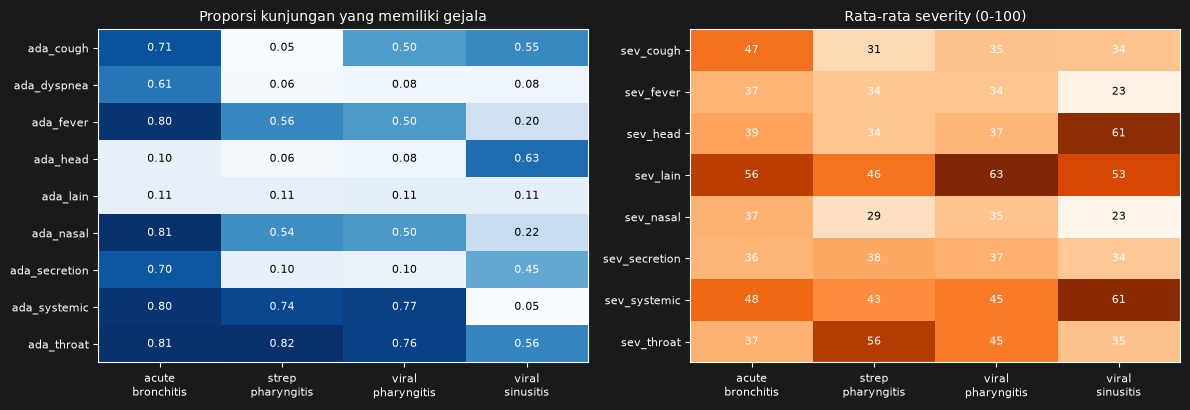

kelompok gejala TANPA kolom severity: ['dyspnea']


In [20]:
def heat(ax, tabel, judul, fmt="{:.2f}", cmap="Blues"):
    """Heatmap sederhana dengan angka di tiap sel (tanpa seaborn)."""
    im = ax.imshow(tabel.values.astype(float), cmap=cmap, aspect="auto")
    ax.set_xticks(range(tabel.shape[1])); ax.set_xticklabels([c.replace("_", "\n") for c in tabel.columns], fontsize=8)
    ax.set_yticks(range(tabel.shape[0])); ax.set_yticklabels(tabel.index, fontsize=8)
    batas = np.nanmax(tabel.values.astype(float)) / 2
    for i in range(tabel.shape[0]):
        for j in range(tabel.shape[1]):
            nilai = tabel.values[i, j]
            if pd.notna(nilai):
                ax.text(j, i, fmt.format(nilai), ha="center", va="center", fontsize=8, color="white" if nilai > batas else "black")
    ax.set_title(judul, fontsize=10)

tr = feat[latih].copy()
ada = [c for c in feat.columns if c.startswith("ada_")]
sev_kol = [c for c in feat.columns if c.startswith("sev_") and c not in ("sev_mean", "sev_max", "sev_n")]
p_ada = (tr[ada] > 0).groupby(tr[TARGET]).mean().T              # proporsi kunjungan yang punya gejala itu
m_sev = tr[sev_kol].groupby(tr[TARGET]).mean().T                # rata-rata severity maks per gejala

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
heat(ax[0], p_ada, "Proporsi kunjungan yang memiliki gejala")
heat(ax[1], m_sev, "Rata-rata severity (0-100)", fmt="{:.0f}", cmap="Oranges")
plt.tight_layout(); plt.show()
print("kelompok gejala TANPA kolom severity:", sorted(set(c.replace("ada_", "") for c in ada) - set(c.replace("sev_", "") for c in sev_kol)))

dua heatmap — (kiri) seberapa sering tiap kelompok gejala muncul di tiap kelas; (kanan) rata-rata tingkat keparahannya.


**Temuan (semuanya sesuai logika klinis, sehingga fitur dapat dipercaya):**
- **`acute_bronchitis`:** batuk (71%), sesak/mengi `dyspnea` (61% — hanya ±8% di kelas lain), dan sekret/dahak (70%) dominan.
- **`viral_sinusitis`:** gejala kepala/wajah (`head`, 63% vs ≤10% di kelas lain) dan keparahan `head` tinggi (61); hampir tidak ada gejala sistemik (5%).
- **`strep_pharyngitis` vs `viral_pharyngitis`** — pasangan tersulit: keduanya nyeri tenggorokan dan gejala sistemik. Pembedanya: **batuk hampir tidak ada pada strep (5%)** vs 50% pada viral; dan **keparahan nyeri tenggorokan lebih tinggi pada strep (56 vs 45)**.
- Kelompok **`lain`** muncul ±11% di *setiap* kelas → tidak membedakan kelas (bukti bahwa ia memang distraktor).
- Kelompok **`dyspnea` tidak punya kolom severity** (tidak pernah dilaporkan skornya), terlihat dari baris terakhir keluaran.


#### 4.2 Umur, jumlah gejala, dan riwayat per kelas

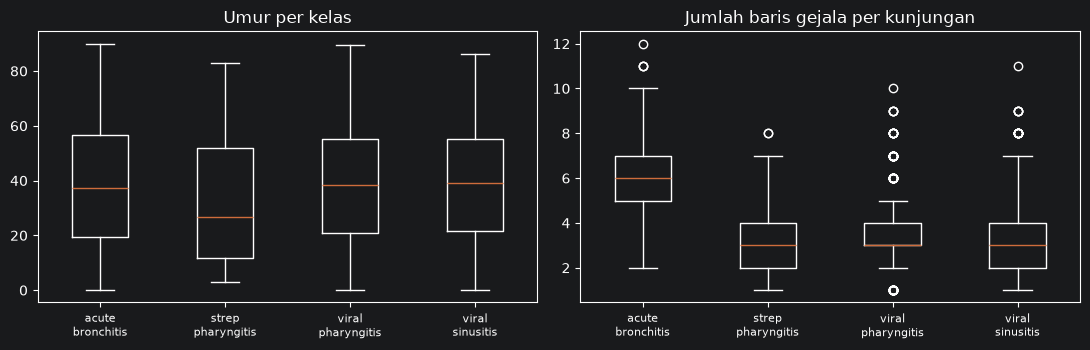

                    age        n_gejala       
                   mean median     mean median
target_class                                  
acute_bronchitis   38.7   37.1      5.7    6.0
strep_pharyngitis  33.2   26.8      3.1    3.0
viral_pharyngitis  38.5   38.2      3.5    3.0
viral_sinusitis    39.3   39.2      3.0    3.0

riwayat (rata-rata per kelas):
target_class          acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
n_conditions                      0.79               0.58               0.64             0.71
n_medications                     0.75               0.48               0.65             0.68
n_procedures                      3.25               3.67               3.14             3.57
n_immunizations                   0.42               0.34               0.32             0.34
n_allergies                       0.00               0.00               0.00             0.00
n_observations                   13.96               9.24               8.9

In [21]:
urut = sorted(tr[TARGET].unique())
tr["n_gejala"] = tr[ada].sum(axis=1)                                    # jumlah baris gejala per kunjungan

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].boxplot([tr.loc[tr[TARGET] == k, "age"].dropna() for k in urut]); ax[0].set_xticklabels([k.replace("_", "\n") for k in urut], fontsize=8)
ax[0].set_title("Umur per kelas")
ax[1].boxplot([tr.loc[tr[TARGET] == k, "n_gejala"] for k in urut]); ax[1].set_xticklabels([k.replace("_", "\n") for k in urut], fontsize=8)
ax[1].set_title("Jumlah baris gejala per kunjungan")
plt.tight_layout(); plt.show()

print(tr.groupby(TARGET)[["age", "n_gejala"]].agg(["mean", "median"]).round(1).to_string())
print("\nriwayat (rata-rata per kelas):")
print(tr[[c for c in tr.columns if c.startswith("n_") and c != "n_gejala"]].groupby(tr[TARGET]).mean().round(2).T.to_string())

> **Alasan — Sel 22**

**Apa:** membandingkan umur, jumlah gejala, dan jumlah riwayat antar kelas.

**Temuan:**
- **Umur:** pasien `strep_pharyngitis` lebih muda (median ±27 tahun vs ±37–39 pada kelas lain; rata-rata 33,2 vs 38,5–39,3). Ini sesuai pengetahuan klinis bahwa radang tenggorokan strep lebih sering pada anak dan remaja, jadi umur adalah fitur yang sah untuk memisahkan strep dari viral pharyngitis.
- **Jumlah gejala:** `acute_bronchitis` punya jauh lebih banyak baris gejala (rata-rata ±5,7 vs ±3,0–3,5). Karena itu jumlah gejala per kelompok (`ada_*`) berguna, bukan hanya ada/tidaknya.
- **Riwayat:** perbedaan antar-kelas kecil dan tidak punya penjelasan klinis yang jelas (mis. `n_observations` ±14 pada bronkitis vs ±9–11 pada kelas lain). Ini konsisten dengan hasil ablasi: riwayat memberi sinyal **tersebar dan lemah**, bukan satu pola kuat.


#### 4.3 Tanda vital per kelas dan nilai tak wajar

In [22]:
vital_kol = [c for c in feat.columns if c.startswith("vital_")]
print("median vital per kelas (median dipakai karena ada outlier yang belum dibersihkan):")
print(tr[vital_kol].groupby(tr[TARGET]).median().round(1).T.to_string())

WAJAR = {"vital_heart_rate": (30, 220), "vital_respiratory_rate": (5, 70), "vital_systolic_bp": (60, 260),
         "vital_diastolic_bp": (30, 150), "vital_spo2": (50, 100), "vital_bmi": (10, 70)}
print("\njumlah nilai di luar rentang wajar (seluruh 5.000 kunjungan):",
      {k: int(((feat[k] < lo) | (feat[k] > hi)).sum()) for k, (lo, hi) in WAJAR.items()})

median vital per kelas (median dipakai karena ada outlier yang belum dibersihkan):
target_class            acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
vital_bmi                           27.9               26.7               27.8             27.8
vital_diastolic_bp                  79.0               78.0               79.0             80.0
vital_heart_rate                    79.0               80.0               81.0             80.0
vital_respiratory_rate              14.0               14.0               14.0             14.0
vital_spo2                          94.0               94.0               94.0             94.0
vital_systolic_bp                  117.0              118.0              118.0            118.0

jumlah nilai di luar rentang wajar (seluruh 5.000 kunjungan): {'vital_heart_rate': 9, 'vital_respiratory_rate': 16, 'vital_systolic_bp': 29, 'vital_diastolic_bp': 24, 'vital_spo2': 42, 'vital_bmi': 13}



**Temuan:** median tiap vital hampir sama di keempat kelas (mis. denyut jantung ±80, laju napas ±14), dan baris terakhir menunjukkan 9–42 nilai tak wajar per vital (total ±130 dari 30.000 nilai, ≈0,4%). Vital **tidak membedakan kelas**; bila ada perbedaan (mis. BMI strep lebih rendah) itu mencerminkan umur yang lebih muda, bukan sinyal vital itu sendiri.


#### 4.4 Urutan baris gejala: bukti dan pengecekan konsistensi train–test

proporsi gejala PERTAMA per kelas:
target_class    acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
gejala_pertama                                                                         
cough                       0.70               0.04               0.48             0.54
dyspnea                     0.16               0.03               0.02             0.01
fever                       0.09               0.49               0.25             0.10
head                        0.00               0.00               0.00             0.19
lain                        0.02               0.07               0.04             0.05
nasal                       0.02               0.20               0.11             0.03
secretion                   0.00               0.01               0.00             0.04
systemic                    0.01               0.13               0.09             0.00
throat                      0.00               0.04               0.02             0.

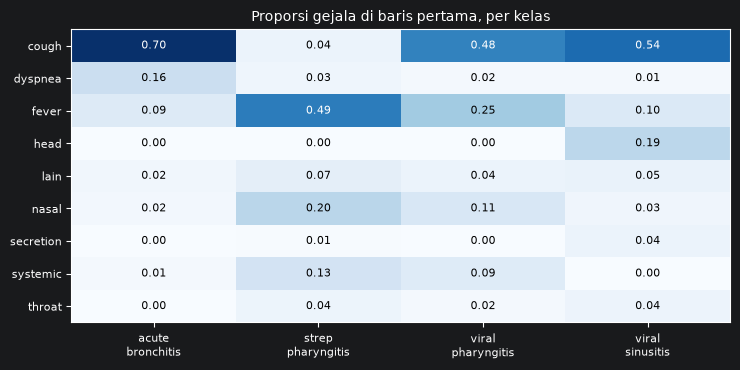

In [23]:
gg = pd.read_csv(TRIASE / "triage_symptoms.csv")                       # urutan baris file asli
gg["kanon"] = norm(gg["symptom_concept"]).map(KANON).fillna("lain")
pertama = gg.groupby(KEY)["kanon"].first()                             # gejala di baris PERTAMA tiap kunjungan
feat["gejala_pertama"] = feat[KEY].map(pertama)
tr["gejala_pertama"] = tr[KEY].map(pertama)

p_pertama = pd.crosstab(tr["gejala_pertama"], tr[TARGET], normalize="columns")      # proporsi per kelas
print("proporsi gejala PERTAMA per kelas:"); print(p_pertama.round(2).to_string())

print("\nPERBANDINGAN: gejala ada kapan saja  vs  gejala ada di baris PERTAMA")
for k in ["fever", "nasal", "head", "cough"]:
    print(f"{k:6s} ada  :", {c: round(float(p_ada.loc[f'ada_{k}', c]), 2) for c in p_ada.columns})
    print(f"{k:6s} pertama:", {c: round(float(p_pertama.loc[k, c]), 2) if k in p_pertama.index else 0 for c in p_pertama.columns})

bagian = np.where(feat[TARGET].notna(), "train", "test")
tabel_tt = pd.crosstab(feat["gejala_pertama"], bagian)
print("\nchi-kuadrat distribusi gejala pertama train vs test: p =", round(chi2_contingency(tabel_tt)[1], 3))

fig, ax = plt.subplots(figsize=(7.5, 3.8)); heat(ax, p_pertama, "Proporsi gejala di baris pertama, per kelas"); plt.tight_layout(); plt.show()
feat = feat.drop(columns="gejala_pertama")          # hanya untuk EDA; bukan fitur model

**Temuan:**
- Distribusi **gejala pertama** sangat berbeda antar kelas meski kehadiran gejalanya mirip. Contoh paling jelas: demam *ada* pada 56% strep dan 50% viral pharyngitis (hampir sama), tetapi demam menjadi gejala **pertama** pada **49%** strep vs **25%** viral pharyngitis. Gejala `head` ada pada 6–10% non-sinusitis, namun **tidak pernah** menjadi gejala pertama pada kelas tersebut (0%) dan menjadi pertama pada 19% sinusitis. Batuk menjadi pertama pada 70% bronkitis.
- Pola ini **konsisten di test**: distribusi gejala pertama train vs test tidak berbeda nyata (χ², p ≈ 0,22), sehingga model yang memakainya dapat menggeneralisasi ke test.



# 5. Modeling

#### 5.1 Konfigurasi model

In [24]:
PARAM = dict(n_estimators=3000, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8,
             subsample_freq=1, colsample_bytree=0.5, class_weight="balanced", random_state=SEED, verbose=-1)
# cadangan bila LightGBM tidak ada: konfigurasi yang dipilih lewat CV (probabilitas lebih terkalibrasi); ketidakseimbangan kelas
# ditangani di bagian 6.2, jadi tanpa class_weight
PARAM_HGB = dict(learning_rate=0.03, max_iter=250, max_leaf_nodes=8, min_samples_leaf=30, l2_regularization=3.0,
                 max_features=0.7, early_stopping=False, categorical_features="from_dtype")

def latih_fold(Xa, ya, Xb, yb, seed):
    """Latih satu model pada fold; kembalikan (model, jumlah iterasi)."""
    if HAS_LGB:
        m = lgb.LGBMClassifier(**{**PARAM, "random_state": seed})
        m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(100, verbose=False)])
        return m, m.best_iteration_
    return HistGradientBoostingClassifier(**PARAM_HGB, random_state=seed).fit(Xa, ya), PARAM_HGB["max_iter"]

print("model:", "LightGBM" )

model: LightGBM


mendefinisikan model gradient boosting dan fungsi pelatihan satu fold.

- Data tabular dengan campuran fitur numerik, kategorikal, banyak `NaN`, dan ratusan kolom TF-IDF yang jarang (*sparse*): pohon menangani `NaN`, skala berbeda, dan interaksi tanpa pra-pemrosesan tambahan.
- Hanya 3.600 sampel: model berkapasitas moderat dengan regularisasi (`num_leaves=15`, `min_child_samples=20`, `subsample=0.8`, `colsample_bytree=0.5`) lebih aman daripada model sangat besar.

`learning_rate=0.03` kecil + `n_estimators=3000` dengan *early stopping* 100 putaran → jumlah pohon ditentukan data, bukan ditebak. `colsample_bytree=0.5` memaksa tiap pohon hanya melihat setengah fitur sehingga tidak terlalu bergantung pada satu kolom TF-IDF. `class_weight="balanced"` memperbesar pengaruh kelas kecil saat pelatihan.


#### 5.2 Cross-validation berulang → prediksi OOF dan prediksi test

In [25]:
oof = np.zeros((len(y), len(KELAS)))                 # prediksi out-of-fold (tiap sampel diprediksi model yang TIDAK melihatnya)
pred_test = np.zeros((len(X_te), len(KELAS)))
penting = pd.Series(0.0, index=X.columns)
for r in range(N_REPEAT):
    for f, (a, b) in enumerate(StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED + r).split(X_tr, y)):
        m, it = latih_fold(X_tr.iloc[a], y[a], X_tr.iloc[b], y[b], SEED + r)
        pb = m.predict_proba(X_tr.iloc[b])
        oof[b] += pb / N_REPEAT
        pred_test += m.predict_proba(X_te) / (N_FOLD * N_REPEAT)
        if HAS_LGB:
            penting += m.feature_importances_ / (N_FOLD * N_REPEAT)
        print(f"ulangan {r} fold {f}: iter {it}, macro-F1 {f1_score(y[b], pb.argmax(1), average='macro'):.4f}")
print("OOF macro-F1 (rata-rata ulangan):", round(f1_score(y, oof.argmax(1), average="macro"), 4))
if HAS_LGB:
    print(penting.sort_values(ascending=False).head(20).round(0))

C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ulangan 0 fold 0: iter 228, macro-F1 0.7106


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ulangan 0 fold 1: iter 230, macro-F1 0.7345


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ulangan 0 fold 2: iter 244, macro-F1 0.7448


... (20 outputs left out)

C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ulangan 2 fold 3: iter 337, macro-F1 0.7611


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ulangan 2 fold 4: iter 201, macro-F1 0.7018
OOF macro-F1 (rata-rata ulangan): 0.7409
sev_throat                 556.0
age                        474.0
sev_nasal                  379.0
income                     378.0
hari_previous_encounter    360.0
vital_systolic_bp          356.0
sev_systemic               339.0
vital_bmi                  338.0
vital_diastolic_bp         332.0
sev_mean                   323.0
sev_max                    307.0
sev_fever                  304.0
vital_heart_rate           303.0
sev_cough                  290.0
hari_procedures            277.0
tf_reports                 269.0
hari_medications           214.0
hari_conditions            214.0
sev_secretion              211.0
vital_spo2                 209.0
dtype: float64


`StratifiedKFold` 5-fold diulang 3 kali dengan pengacakan berbeda (15 model). Tiap sampel train mendapat prediksi dari model yang **tidak pernah melihatnya** (OOF), dirata-rata atas 3 ulangan. Prediksi test adalah rata-rata dari ke-15 model.

- **Stratified:** kelas `strep` hanya 195 sampel; tanpa stratifikasi, sebuah fold bisa kebetulan hanya berisi 25 atau 55 sampel strep.
- **Tidak perlu `GroupKFold`:** satu pasien = satu baris (terbukti di 2.3 dan 3.2), jadi tidak ada kebocoran antar-fold lewat pasien yang sama.
- **Diulang 3×:** dengan 39 sampel strep per fold, skor satu kali CV sangat berisik (skor per fold bervariasi 0,67–0,76 pada keluaran referensi). Merata-ratakan ulangan menstabilkan OOF dan, nanti, bobot kelas.
- **OOF (bukan skor train):** satu-satunya estimasi jujur performa pada data baru.
- **Rata-rata 15 model untuk test:** memangkas varians tanpa melatih ulang pada seluruh data; tiap model sudah dilatih pada 80% data.

**Temuan [run referensi, HistGradientBoosting]:** OOF macro-F1 **0,712** sebelum bobot kelas; skor per fold bervariasi 0,67–0,76 (menunjukkan seberapa berisik evaluasi pada data sekecil ini).


# 6. Evaluasi

## 6.1 Kinerja OOF sebelum penyesuaian bobot kelas

#### 6.1.1 Laporan klasifikasi dan confusion matrix (argmax probabilitas)

OOF macro-F1: 0.7409 | AUC macro (OvR): 0.951
                   precision    recall  f1-score   support

 acute_bronchitis      0.889     0.868     0.878       940
strep_pharyngitis      0.430     0.379     0.403       195
viral_pharyngitis      0.744     0.778     0.761       985
  viral_sinusitis      0.921     0.922     0.921      1480

         accuracy                          0.839      3600
        macro avg      0.746     0.737     0.741      3600
     weighted avg      0.838     0.839     0.838      3600



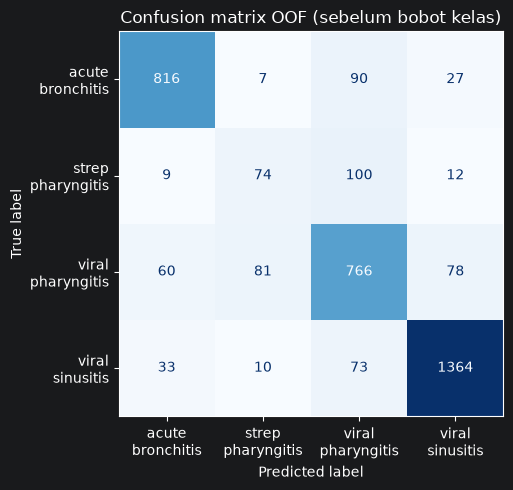

In [26]:
pred_raw = oof.argmax(1)
print("OOF macro-F1:", round(f1_score(y, pred_raw, average="macro"), 4), "| AUC macro (OvR):", round(roc_auc_score(y, oof, multi_class="ovr", average="macro"), 4))
print(classification_report(y, pred_raw, target_names=KELAS, digits=3))

fig, ax = plt.subplots(figsize=(5.8, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_raw), display_labels=[k.replace("_", "\n") for k in KELAS]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix OOF (sebelum bobot kelas)"); plt.tight_layout(); plt.show()

metrik per kelas (precision, recall, F1) dan confusion matrix dari prediksi OOF.

**Temuan :**
- `viral_sinusitis` (F1 ±0,92) dan `acute_bronchitis` (±0,88) mudah — gejalanya khas (kepala/wajah dan batuk/sesak).
- `viral_pharyngitis` sedang (±0,77) dan `strep_pharyngitis` sangat rendah (F1 ±0,27; **recall hanya ±19%**): dari 195 kasus strep, hanya sekitar 37 yang terdeteksi; sebagian besar disalahklasifikasikan sebagai `viral_pharyngitis`.
- Secara klinis ini masuk akal: strep dan viral pharyngitis memang hampir identik pada gejala (keduanya nyeri tenggorokan + gejala sistemik) dan hanya dibedakan oleh batuk, keparahan nyeri tenggorokan, dan umur.
- AUC macro tinggi (0,952) sementara F1 strep rendah: model **mengurutkan** kasus strep dengan baik, tetapi **ambang keputusan** argmax terlalu konservatif untuk kelas 5%. Inilah motivasi langkah berikutnya.

## 6.2 Penyesuaian bobot kelas untuk macro-F1

#### 6.2.1 Mencari bobot kelas pada OOF + uji kestabilan

In [27]:
MIN_GAIN = 0.001                       # kenaikan <= ini dianggap noise -> bobot diabaikan
KANDIDAT = np.round(np.arange(0.5, 2.51, 0.05), 2)

def f1_bobot(yy, PP, w):
    return f1_score(yy, (PP * w).argmax(1), average="macro")

def cari_bobot(yy, PP, passes=3):
    """Koordinat demi koordinat: ubah bobot satu kelas, ambil yang memaksimalkan macro-F1."""
    w = np.ones(PP.shape[1])
    for _ in range(passes):
        for k in range(len(w)):
            skor = [f1_bobot(yy, PP, np.where(np.arange(len(w)) == k, c, w)) for c in KANDIDAT]
            w[k] = KANDIDAT[int(np.argmax(skor))]
    return w

w = cari_bobot(y, oof)
f1_awal, f1_akhir = f1_bobot(y, oof, np.ones(len(KELAS))), f1_bobot(y, oof, w)
gain = f1_akhir - f1_awal
w_pakai = w if gain > MIN_GAIN else np.ones(len(KELAS))
print("bobot:", {k: float(round(b, 2)) for k, b in zip(KELAS, w)})
print(f"macro-F1 OOF: {f1_awal:.4f} -> {f1_akhir:.4f} (gain {gain:+.4f}) | dipakai: {'ya' if gain > MIN_GAIN else 'TIDAK (gain terlalu kecil)'}")

# uji kestabilan: bobot disetel di separuh data, dinilai di separuh lain (gain harus tetap positif)
rng, gains = np.random.RandomState(0), []
for _ in range(10):
    idx = rng.permutation(len(y)); i1, i2 = idx[: len(y) // 2], idx[len(y) // 2:]
    w1 = cari_bobot(y[i1], oof[i1])
    gains.append(f1_bobot(y[i2], oof[i2], w1) - f1_bobot(y[i2], oof[i2], np.ones(len(KELAS))))
print(f"gain pada data yang tidak dipakai menyetel: rata-rata {np.mean(gains):+.4f}, terendah {np.min(gains):+.4f}")

bobot: {'acute_bronchitis': 0.65, 'strep_pharyngitis': 0.9, 'viral_pharyngitis': 1.0, 'viral_sinusitis': 0.95}
macro-F1 OOF: 0.7409 -> 0.7491 (gain +0.0082) | dipakai: ya
gain pada data yang tidak dipakai menyetel: rata-rata -0.0025, terendah -0.0139


mengalikan probabilitas tiap kelas dengan sebuah bobot sebelum `argmax`, lalu mencari bobot yang memaksimalkan macro-F1 pada OOF (satu kelas demi satu kelas, 3 putaran).

**Alasan:** `argmax` pada probabilitas yang tidak dibobot mengoptimalkan *akurasi*, bukan macro-F1. Untuk kelas 5%, probabilitas strep jarang melampaui kelas lain meski kasusnya sebenarnya strep. Menaikkan bobot strep memindahkan ambang keputusan sehingga lebih banyak kasus strep tertangkap, dengan mengorbankan sedikit presisi. Karena macro-F1 menimbang kelas kecil sama dengan kelas besar, pertukaran ini menguntungkan.

**Temuan [run referensi, HGB tanpa class_weight]:** bobot `acute_bronchitis` 0,85; `strep` **1,70**; `viral_pharyngitis` 1,00; `viral_sinusitis` **0,50**. Macro-F1 OOF naik **0,7120 → 0,7412 (+0,029)**; pada data yang tidak dipakai menyetel gain tetap **+0,021 rata-rata dan tidak pernah negatif (minimum +0,008)** → peningkatannya nyata, bukan sekadar overfit.


#### 6.2.2 Hasil setelah bobot kelas

OOF macro-F1 setelah bobot: 0.7491
                   precision    recall  f1-score   support

 acute_bronchitis      0.921     0.843     0.880       940
strep_pharyngitis      0.474     0.379     0.422       195
viral_pharyngitis      0.734     0.813     0.771       985
  viral_sinusitis      0.920     0.927     0.923      1480

         accuracy                          0.844      3600
        macro avg      0.762     0.741     0.749      3600
     weighted avg      0.845     0.844     0.843      3600

                   F1 sebelum  F1 sesudah  recall sebelum  recall sesudah
acute_bronchitis        0.878       0.880           0.868           0.843
strep_pharyngitis       0.403       0.422           0.379           0.379
viral_pharyngitis       0.761       0.771           0.778           0.813
viral_sinusitis         0.921       0.923           0.922           0.927


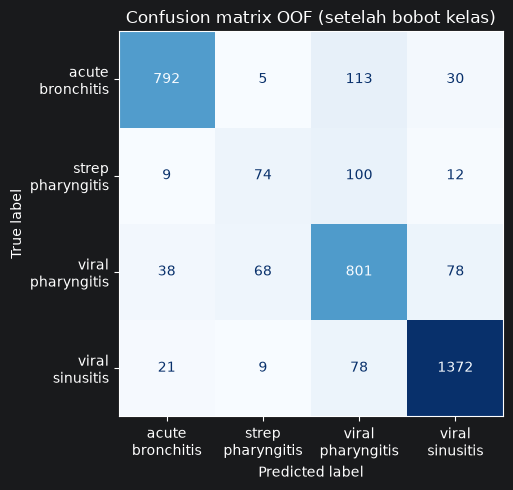

In [28]:
pred_w = (oof * w_pakai).argmax(1)
print("OOF macro-F1 setelah bobot:", round(f1_score(y, pred_w, average="macro"), 4))
print(classification_report(y, pred_w, target_names=KELAS, digits=3))

banding = pd.DataFrame({
    "F1 sebelum": f1_score(y, pred_raw, average=None), "F1 sesudah": f1_score(y, pred_w, average=None),
    "recall sebelum": [(pred_raw[y == k] == k).mean() for k in range(len(KELAS))],
    "recall sesudah": [(pred_w[y == k] == k).mean() for k in range(len(KELAS))]}, index=KELAS).round(3)
print(banding.to_string())

fig, ax = plt.subplots(figsize=(5.8, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_w), display_labels=[k.replace("_", "\n") for k in KELAS]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix OOF (setelah bobot kelas)"); plt.tight_layout(); plt.show()

Ini adalah laporan klasifikasi dan confusion matrix setelah bobot, plus tabel perbandingan F1 dan recall tiap kelas sebelum/sesudah.

**Temuan:** recall strep naik dari **19% menjadi 38%** dan F1 strep dari **0,269 menjadi 0,399** (presisinya turun dari 0,46 ke 0,42). Sebagai gantinya, kelas besar turun sedikit: recall `viral_sinusitis` dari 94,5% ke 89,6% (F1 0,922 → 0,915), sedangkan `acute_bronchitis` dan `viral_pharyngitis` hampir tidak berubah. Karena macro-F1 menimbang keempat kelas sama, kenaikan +0,13 pada F1 strep lebih besar daripada penurunan kecil di kelas besar — itulah sumber gain +0,029.


## 6.3 Seberapa pasti skornya?

## 6.4 Ablasi: apa yang sebenarnya memberi sinyal?

#### 6.4.1 Ablasi blok fitur (opsional, `RUN_ABLATION`)

In [29]:
REFERENSI = pd.DataFrame([   # hasil run verifikasi: HistGradientBoosting, 5-fold, 1 ulangan (SEED), bobot kelas disetel pada OOF yang sama
    ("A  final (TF-IDF urutan asli)",         707, 0.7178, 0.7357, 0.9513),
    ("B  tanpa TF-IDF sama sekali",            46, 0.6898, 0.7177, 0.9455),
    ("C  TF-IDF, URUTAN gejala diacak",      1043, 0.6906, 0.7237, 0.9459),
    ("D  TF-IDF hanya teks keluhan",           64, 0.6924, 0.7115, 0.9452),
    ("E  final tanpa vital_*",                701, 0.7113, 0.7460, 0.9522),
    ("F  final tanpa riwayat (n_*, hari_*)",  694, 0.7039, 0.7273, 0.9474),
], columns=["varian", "n_kolom", "F1_mentah", "F1_setelah_bobot", "AUC"]).set_index("varian")

if RUN_ABLATION:
    def bangun_X(teks, buang_awalan=(), pakai_tfidf=True):
        f = feat.copy(); f["teks"] = teks
        bagian = [f.drop(columns=BUANG)]
        if pakai_tfidf:
            tf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(f["teks"])
            bagian.append(pd.DataFrame(tf.transform(f["teks"]).toarray(), columns="tf_" + tf.get_feature_names_out()))
        Xa = pd.concat(bagian, axis=1); Xa.columns = Xa.columns.str.replace(r"[^A-Za-z0-9_]", "_", regex=True)
        Xa = Xa.drop(columns=[c for c in Xa.columns if Xa[c].nunique(dropna=True) <= 1])
        if buang_awalan:
            Xa = Xa.drop(columns=[c for c in Xa.columns if c.startswith(tuple(buang_awalan))])
        return Xa[latih].reset_index(drop=True)

    g_acak = g.sample(frac=1, random_state=0)                                  # urutan baris gejala diacak
    VARIAN = {
        "A  final (TF-IDF urutan asli)":  lambda: bangun_X(feat["teks"]),
        "B  tanpa TF-IDF sama sekali":    lambda: bangun_X(feat["teks"], pakai_tfidf=False),
        "C  TF-IDF, URUTAN gejala diacak": lambda: bangun_X(fitur_teks(g_acak, keluhan, feat[KEY])),
        "D  TF-IDF hanya teks keluhan":   lambda: bangun_X(" || " + norm(feat[KEY].map(keluhan).fillna(""))),
        "E  final tanpa vital_*":         lambda: bangun_X(feat["teks"], buang_awalan=("vital_",)),
        "F  final tanpa riwayat (n_*, hari_*)": lambda: bangun_X(feat["teks"], buang_awalan=("n_", "hari_")),
    }
    baris = []
    for nama, bangun in VARIAN.items():
        Xa = bangun(); o = np.zeros((len(y), len(KELAS)))
        for a, b in StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED).split(Xa, y):
            o[b] = HistGradientBoostingClassifier(**PARAM_HGB, random_state=SEED).fit(Xa.iloc[a], y[a]).predict_proba(Xa.iloc[b])
        wa = cari_bobot(y, o)
        baris.append((nama, Xa.shape[1], f1_score(y, o.argmax(1), average="macro"), f1_bobot(y, o, wa),
                      roc_auc_score(y, o, multi_class="ovr", average="macro")))
        print(f"{nama:40s} kolom={Xa.shape[1]:4d} F1={baris[-1][2]:.4f} F1+bobot={baris[-1][3]:.4f} AUC={baris[-1][4]:.4f}")
    REFERENSI = pd.DataFrame(baris, columns=REFERENSI.reset_index().columns).set_index("varian")
else:
    print("RUN_ABLATION=False -> menampilkan hasil run referensi (set True untuk menjalankan ulang, ±6 menit).")
REFERENSI.round(4)

RUN_ABLATION=False -> menampilkan hasil run referensi (set True untuk menjalankan ulang, ±6 menit).


,n_kolom,F1_mentah,F1_setelah_bobot,AUC
varian,,,,
A final (TF-IDF urutan asli),707,0.7178,0.7357,0.9513
B tanpa TF-IDF sama sekali,46,0.6898,0.7177,0.9455
"C TF-IDF, URUTAN gejala diacak",1043,0.6906,0.7237,0.9459
D TF-IDF hanya teks keluhan,64,0.6924,0.7115,0.9452
E final tanpa vital_*,701,0.7113,0.7460,0.9522
"F final tanpa riwayat (n_*, hari_*)",694,0.7039,0.7273,0.9474



**Temuan dan cara membacanya:**
| Perbandingan | Kesimpulan |
|---|---|
| **A vs B** (ada/tidak TF-IDF): AUC 0,9513 vs 0,9455; F1+bobot 0,7357 vs 0,7177 | TF-IDF memberi peningkatan nyata (±+0,006 AUC, ±+0,018 F1) |
| **A vs C** (urutan asli vs diacak): AUC 0,9513 vs 0,9459 | Jika urutan baris gejala diacak, seluruh keuntungan TF-IDF **hilang** (C ≈ B). Keuntungannya berasal dari **urutan**, bukan dari kata-katanya |
| **A vs D** (TF-IDF hanya dari keluhan): AUC 0,9452 | Teks keluhan utama tidak menyumbang apa-apa (D ≈ B) |
| **A vs E** (tanpa vital): AUC 0,9522 vs 0,9513 | Vital **tidak berkontribusi**; menghapusnya sama saja atau sedikit lebih baik |
| **A vs F** (tanpa riwayat): AUC 0,9474 vs 0,9513; F1+bobot 0,7273 vs 0,7357 | Riwayat memberi sinyal **nyata namun kecil**, tersebar di banyak tabel |


# 7. Submission

#### Sel 32 · Membuat file submission

In [30]:
contoh = pd.read_csv(DATA / "sample_submission.csv")
hasil = pd.DataFrame({ID: test[ID], TARGET: np.array(KELAS)[(pred_test * w_pakai).argmax(1)]})
sub_df = contoh[[ID]].merge(hasil, on=ID, how="left")
assert len(sub_df) == len(contoh) and sub_df[TARGET].notna().all(), "ID test tidak cocok dengan sample_submission"
sub_df.to_csv(OUT / "submission.csv", index=False)
pd.DataFrame(oof, columns=KELAS).assign(**{ID: train[ID].to_numpy()}).to_csv(OUT / "oof_model.csv", index=False)

banding_prior = pd.DataFrame({"proporsi test (prediksi)": sub_df[TARGET].value_counts(normalize=True),
                              "proporsi train (asli)": train[TARGET].value_counts(normalize=True)}).round(3)
print(banding_prior.to_string()); print("tersimpan:", OUT / "submission.csv")

                   proporsi test (prediksi)  proporsi train (asli)
target_class                                                      
viral_sinusitis                       0.384                  0.411
viral_pharyngitis                     0.325                  0.274
acute_bronchitis                      0.242                  0.261
strep_pharyngitis                     0.049                  0.054
tersimpan: \outputs\submission.csv


 menerapkan bobot kelas pada prediksi test, memetakan indeks kelas kembali ke nama, lalu menyimpan `submission.csv` (dan OOF untuk analisis lanjutan).

